##### Citation Info
@InProceedings{Gushchin_2026_CVPR,
    author    = {Gushchin, Aleksandr and Abud, Khaled and Shumitskaya, Ekaterina and Filippov, Artem and Bychkov, Georgii and Lavrushkin, Sergey and Erofeev, Mikhail and Antsiferova, Anastasia and Chen, Changsheng and Tan, Shunquan and Timofte, Radu and Vatolin, Dmitriy and Song, Chuanbiao and Yu, Zijian and Tan, Hao and Lan, Jun and Yang, Zhiqiang and Tang, Yongwei and Wu, Zhiqiang and Seow, Jia Wen and Koay, Hong Vin and Ren, Haodong and Xu, Feng and Chen, Shuai and Xia, Ruiyang and Zhang, Qi and Xu, Yaowen and Zou, Zhaofan and Sun, Hao and Lu, Dagong and Yao, Mufeng and Xu, Xinlei and Wu, Fei and Guo, Fengjun and Luo, Cong and Sharma, Hardik and Negi, Aashish and Shaily, Prateek and Kumar, Jayant and Chaudhary, Sachin and Dudhane, Akshay and Hambarde, Praful and Shukla, Amit and Tu, Zhilin and Li, Fengpeng and Zhang, Jiamin and Fei, Jianwei and Li, Kemou and Wu, Haiwei and Benjdira, Bilel and Ali, Anas M. and Boulila, Wadii and Qu, Chenfan and Li, Junchi},
    title     = {NTIRE 2026 Challenge on Robust AI-Generated Image Detection in the Wild},
    booktitle = {Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR) Workshops},
    month     = {June},
    year      = {2026},
    pages     = {1895-1913}
}


In [1]:
import torch
import torchvision

# check NVIDIA GPU available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
# Set up image transforms, datasets, and data loaders

from torch.utils.data import DataLoader
from torchvision.models import ViT_B_16_Weights
from aigendet_dataset import AIGenDetDataset

transform = ViT_B_16_Weights.DEFAULT.transforms()

batch_size = 32

train_path = "../data/train"
train_shard_nums = [0, 5] # list of training shards to use (0-5)
train = AIGenDetDataset(train_path, train_shard_nums, transform=transform)
val = AIGenDetDataset(
    image_dir="../data/val/val/val_images",
    labels_csv="../data/val/val/val_labels.csv",
    transform=transform,
)
val_hard = AIGenDetDataset(
    image_dir="../data/val/val_hard/val_images_hard",
    labels_csv="../data/val/val_hard/val_hard_labels.csv",
    transform=transform,
)
test = AIGenDetDataset(
    image_dir="../data/test/test_images",
    labels_csv="../data/test/test_labels.csv",
    transform=transform,
)

trainloader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=8, pin_memory=True, persistent_workers=True)
valloader = DataLoader(val, batch_size=batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)
val_hardloader = DataLoader(val_hard, batch_size=batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)

# Creating this loader does not run test evaluation.
testloader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)


Found 2 shards, 77643 images in total.
Found 10000 images in ../data/val/val/val_images.
Found 2500 images in ../data/val/val_hard/val_images_hard.
Found 2500 images in ../data/test/test_images.


In [3]:
# Set up model for fine tuning

import torch.nn as nn
from torchvision.models import vit_b_16, ViT_B_16_Weights

model = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)
print(model)

# Replace the final layer with a new one that has 2 output classes
num_features = model.heads.head.in_features
model.heads.head = nn.Linear(num_features, 2)

for name, parameter in model.named_parameters():
    parameter.requires_grad = name.startswith(("heads.head", "encoder.layers.encoder_layer_11", "encoder.layers.encoder_layer_10", "encoder.layers.encoder_layer_9",))

model.to(device)

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine

In [4]:
# set up optimizer

import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([
    {"params": model.heads.head.parameters(), "lr": 1e-4},
    {"params": model.encoder.layers.encoder_layer_11.parameters(), "lr": 1e-5},
    {"params": model.encoder.layers.encoder_layer_10.parameters(), "lr": 1e-5},
    {"params": model.encoder.layers.encoder_layer_9.parameters(), "lr": 1e-5}
])

In [5]:
# Train/eval loop
from sklearn.metrics import roc_auc_score

best_roc_auc = float('-inf')
miss_count = 0
max_misses = 5

for epoch in range(50):
    model.train()
    
    running_loss = 0.0
    for i, batch in enumerate(trainloader, 0):
        images = batch["image"].to(device)
        binary_labels = batch["label"].to(device)
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, binary_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 250 == 249:    # print every 250 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 250:.6f}')
            running_loss = 0.0
    print(f'Finished epoch {epoch + 1}')
    
    # Validation
    model.eval()
    y_true, y_ai_probability = [], []

    with torch.no_grad():
        for batch in valloader:
            images = batch["image"].to(device)
            ai_probability = model(images).softmax(dim=1)[:, 1]

            y_true.extend(batch["label"].tolist())
            y_ai_probability.extend(ai_probability.cpu().tolist())

    val_roc_auc = roc_auc_score(y_true, y_ai_probability)
    print(f"Validation ROC AUC: {val_roc_auc:.6f}")

    if val_roc_auc > best_roc_auc:
        best_roc_auc = val_roc_auc
        miss_count = 0
        torch.save(model, "../models/ViT-B-16FineTuned.pth")
    else:
        miss_count += 1
        if miss_count >= max_misses:
            print("ROC AUC stopped improving, stopping early.")
            break

print('Finished Training')

[1,   250] loss: 0.543873
[1,   500] loss: 0.364361
[1,   750] loss: 0.322124
[1,  1000] loss: 0.305955
[1,  1250] loss: 0.294391
[1,  1500] loss: 0.275736
[1,  1750] loss: 0.266368
[1,  2000] loss: 0.260382
[1,  2250] loss: 0.267602
Finished epoch 1
Validation ROC AUC: 0.870560
[2,   250] loss: 0.216335
[2,   500] loss: 0.206176
[2,   750] loss: 0.210594
[2,  1000] loss: 0.204580
[2,  1250] loss: 0.209135
[2,  1500] loss: 0.210707
[2,  1750] loss: 0.204146
[2,  2000] loss: 0.198901
[2,  2250] loss: 0.193879
Finished epoch 2
Validation ROC AUC: 0.884823
[3,   250] loss: 0.153049
[3,   500] loss: 0.154352
[3,   750] loss: 0.151675
[3,  1000] loss: 0.160716
[3,  1250] loss: 0.147380
[3,  1500] loss: 0.156098
[3,  1750] loss: 0.147436
[3,  2000] loss: 0.151279
[3,  2250] loss: 0.153974
Finished epoch 3
Validation ROC AUC: 0.888419
[4,   250] loss: 0.102779
[4,   500] loss: 0.100392
[4,   750] loss: 0.101078
[4,  1000] loss: 0.105822
[4,  1250] loss: 0.105034
[4,  1500] loss: 0.110703
[4, 


Overall: 10000 images
              precision    recall  f1-score   support

        Real      0.791     0.823     0.807      5000
AI-generated      0.816     0.783     0.799      5000

    accuracy                          0.803     10000
   macro avg      0.803     0.803     0.803     10000
weighted avg      0.803     0.803     0.803     10000

Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):
[[4115  885]
 [1087 3913]]
Balanced accuracy: 0.8028
Brier score (lower is better): 0.1468
Log loss (lower is better): 0.5113
ROC-AUC (higher is better): 0.888419

Clean: 5000 images
              precision    recall  f1-score   support

        Real      0.831     0.856     0.843      2500
AI-generated      0.852     0.826     0.839      2500

    accuracy                          0.841      5000
   macro avg      0.841     0.841     0.841      5000
weighted avg      0.841     0.841     0.841      5000

Confusion matrix (rows: actual, columns: predicted; order: R

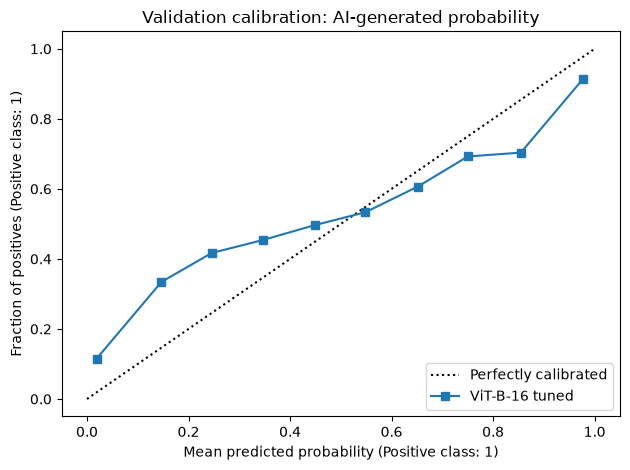

In [6]:
# Get detailed metrics for the current model on the validation set
model = torch.load('../models/ViT-B-16FineTuned.pth', map_location=device, weights_only=False)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

y_true, y_pred, y_ai_probability, is_distorted = [], [], [], []

model.eval()
with torch.no_grad():
    for batch in valloader:
        images = batch["image"].to(device)
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch["label"].to(device).tolist())
        y_pred.extend(predictions.tolist())
        # Class 1 is AI-generated; use its probability for every image.
        y_ai_probability.extend(probabilities[:, 1].tolist())
        is_distorted.extend(batch["is_distorted"].tolist())

# Keep the labels, predictions, scores, and distortion flags aligned.
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_ai_probability = np.asarray(y_ai_probability)
is_distorted = np.asarray(is_distorted)

# Classification uses the existing argmax decision (equivalent to threshold 0.5,
# with ties assigned to Real). ROC AUC uses continuous AI probabilities.
for subset_name, mask in [
    ("Overall", np.ones(len(y_true), dtype=bool)),
    ("Clean", is_distorted == 0),
    ("Distorted (robustness)", is_distorted == 1),
]:
    print(f"\n{subset_name}: {mask.sum()} images")
    if not mask.any():
        print("No images in this subset; skipping metrics.")
        continue

    labels = y_true[mask]
    predicted = y_pred[mask]
    scores = y_ai_probability[mask]
    print(classification_report(
        labels,
        predicted,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        digits=3,
        zero_division=0,
    ))
    print("Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):")
    print(confusion_matrix(labels, predicted, labels=[0, 1]))
    print(f"Balanced accuracy: {balanced_accuracy_score(labels, predicted):.4f}")
    print(f"Brier score (lower is better): {brier_score_loss(labels, scores):.4f}")
    print(f"Log loss (lower is better): {log_loss(labels, scores, labels=[0, 1]):.4f}")
    if len(np.unique(labels)) == 2:
        print(f"ROC-AUC (higher is better): {roc_auc_score(labels, scores):.6f}")
    else:
        print("ROC-AUC is undefined: this subset contains only one class.")

# Near the diagonal means predicted AI probabilities match observed AI frequencies.
CalibrationDisplay.from_predictions(
    y_true,
    y_ai_probability,
    n_bins=10,
    strategy="uniform",
    name="ViT-B-16 tuned",
)
plt.title("Validation calibration: AI-generated probability")
plt.tight_layout()
plt.show()



Overall: 2500 images
              precision    recall  f1-score   support

        Real      0.659     0.757     0.704      1250
AI-generated      0.714     0.608     0.657      1250

    accuracy                          0.682      2500
   macro avg      0.687     0.682     0.681      2500
weighted avg      0.687     0.682     0.681      2500

Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):
[[946 304]
 [490 760]]
Balanced accuracy: 0.6824
Brier score (lower is better): 0.2425
Log loss (lower is better): 0.8881
ROC-AUC (higher is better): 0.755983

Clean: 1250 images
              precision    recall  f1-score   support

        Real      0.702     0.741     0.721       625
AI-generated      0.725     0.685     0.705       625

    accuracy                          0.713      1250
   macro avg      0.713     0.713     0.713      1250
weighted avg      0.713     0.713     0.713      1250

Confusion matrix (rows: actual, columns: predicted; order: Real, 

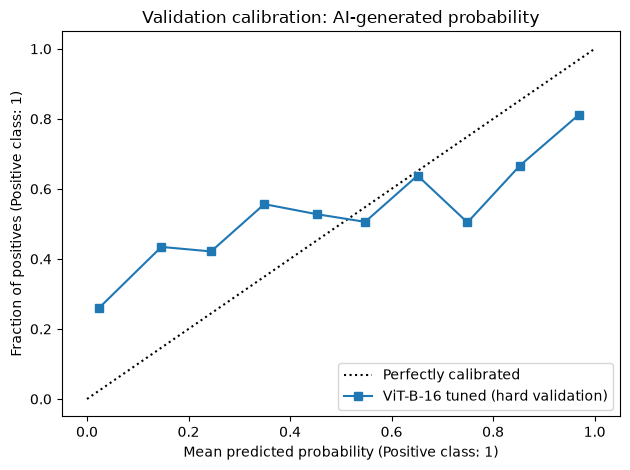

In [7]:
# Get detailed metrics for the current model on the hard validation set
model = torch.load('../models/ViT-B-16FineTuned.pth', map_location=device, weights_only=False)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

y_true, y_pred, y_ai_probability, is_distorted = [], [], [], []

model.eval()
with torch.no_grad():
    for batch in val_hardloader:
        images = batch["image"].to(device)
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch["label"].to(device).tolist())
        y_pred.extend(predictions.tolist())
        # Class 1 is AI-generated; use its probability for every image.
        y_ai_probability.extend(probabilities[:, 1].tolist())
        is_distorted.extend(batch["is_distorted"].tolist())

# Keep the labels, predictions, scores, and distortion flags aligned.
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_ai_probability = np.asarray(y_ai_probability)
is_distorted = np.asarray(is_distorted)

# Classification uses the existing argmax decision (equivalent to threshold 0.5,
# with ties assigned to Real). ROC AUC uses continuous AI probabilities.
for subset_name, mask in [
    ("Overall", np.ones(len(y_true), dtype=bool)),
    ("Clean", is_distorted == 0),
    ("Distorted (robustness)", is_distorted == 1),
]:
    print(f"\n{subset_name}: {mask.sum()} images")
    if not mask.any():
        print("No images in this subset; skipping metrics.")
        continue

    labels = y_true[mask]
    predicted = y_pred[mask]
    scores = y_ai_probability[mask]
    print(classification_report(
        labels,
        predicted,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        digits=3,
        zero_division=0,
    ))
    print("Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):")
    print(confusion_matrix(labels, predicted, labels=[0, 1]))
    print(f"Balanced accuracy: {balanced_accuracy_score(labels, predicted):.4f}")
    print(f"Brier score (lower is better): {brier_score_loss(labels, scores):.4f}")
    print(f"Log loss (lower is better): {log_loss(labels, scores, labels=[0, 1]):.4f}")
    if len(np.unique(labels)) == 2:
        print(f"ROC-AUC (higher is better): {roc_auc_score(labels, scores):.6f}")
    else:
        print("ROC-AUC is undefined: this subset contains only one class.")

# Near the diagonal means predicted AI probabilities match observed AI frequencies.
CalibrationDisplay.from_predictions(
    y_true,
    y_ai_probability,
    n_bins=10,
    strategy="uniform",
    name="ViT-B-16 tuned (hard validation)",
)
plt.title("Validation calibration: AI-generated probability")
plt.tight_layout()
plt.show()
